In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
from parnassus_core.experiments.cms_2011.performance.performance import Performance
from parnassus_core.experiments.cms_2011.performance.config import (
    PerformanceConfig,
    Sample,
)

In [4]:
config_dict = {
    "samples": {
        "ttbar": [
            {
                "name": "parnassus",
                "path": "../evaluation/evals/parnassus_core_ip_noself_ttbar_eval_49k_test_eta25Eval.root",
                "pflow_type": "fm",
                "label": "Parnassus (FM)",
            },
        ],
        "h4lep": [
            {
                "name": "parnassus",
                "path": "../evaluation/evals/parnassus_core_ip_noself_h4lep_49k_test_eta25Eval.root",
                "pflow_type": "fm",
                "label": "Parnassus (FM)",
            },
        ],
    }
}

In [5]:
config = PerformanceConfig.from_dict(config_dict)

In [6]:
perf = Performance(config)

In [7]:
config.sample_dict.keys()

dict_keys([<Sample.TTBAR: 'ttbar'>, <Sample.H4LEP: 'h4lep'>])

In [8]:
perf.load()

Loading data for parnassus from ../evaluation/evals/parnassus_core_ip_noself_ttbar_eval_49k_test_eta25Eval.root
Loading data for parnassus from ../evaluation/evals/parnassus_core_ip_noself_h4lep_49k_test_eta25Eval.root


In [9]:
perf.sample_data_dict[Sample.TTBAR].filter_events()

Filtering events for PF with source Source.PF
Data(name=PF, source=Source.PF), events filtered: 49971
Filtering events for TR with source Source.TR
Data(name=TR, source=Source.TR), events filtered: 49971
Filtering events for parnassus with source Source.FM
Data(name=parnassus, source=Source.FM), events filtered: 49971


In [10]:
perf.sample_data_dict[Sample.TTBAR].data_dict["PF"].particle_data_jet["pf_idx"][1310]

array([ 0,  1,  2,  3,  4,  5,  6,  7,  8,  9, 10, 11, 12, 13, 14, 15, 16,
       17, 18, 19, 20, 21, 22, 23, 24, 25, 26, 27, 28, 29, 30, 31, 32, 33,
       34, 35, 36, 37, 38, 39, 40, 41, 42, 43, 44, 45, 46, 47, 48, 49, 50])

In [11]:
perf.sample_data_dict[Sample.TTBAR].data_dict["PF"].particle_data_jet["pt"][1310]

array([44.19238663,  3.04434824,  1.11722028,  1.08236682])

In [12]:
perf.sample_data_dict[Sample.TTBAR].process_data()

Calculating event data for PF with source Source.PF
Calculating event data for TR with source Source.TR
Calculating event data for parnassus with source Source.FM
Processing data for PF with source Source.PF
Calculating event residuals for PF with source Source.PF against TR with source Source.TR
Matching jets for PF with source Source.PF against TR with source Source.TR


Matching jets: 100%|██████████| 49971/49971 [00:04<00:00, 11866.52it/s]


Calculating jet residuals for PF with source Source.PF against TR with source Source.TR


residuals: 100%|██████████| 49971/49971 [00:00<00:00, 65705.17it/s]


Calculating particle residuals for PF with source Source.PF against TR with source Source.TR
Split:  all


residuals: 100%|██████████| 49971/49971 [00:00<00:00, 62083.68it/s]


... (11 outputs left out)

residuals: 100%|██████████| 49971/49971 [00:00<00:00, 63562.26it/s]


Split:  bkg


residuals: 100%|██████████| 49971/49971 [00:00<00:00, 64087.60it/s]


Processed data for sample TTBAR


In [13]:
perf.process()

Processing sample: TTBAR
Skipping filter_events: events already filtered
Skipping calculate_event_data: event data already calculated
Skipping calculate_event_data: event data already calculated
Skipping calculate_event_data: event data already calculated
Processing data for PF with source Source.PF
Skipping calculate_event_residuals: event residuals already calculated
Skipping match_jets: jets already matched
Skipping calculate_jet_residuals: jet residuals already calculated
Skipping calculate_particle_residuals: particle residuals already calculated
Processing data for parnassus with source Source.FM
Skipping calculate_event_residuals: event residuals already calculated
Skipping match_jets: jets already matched
Skipping calculate_jet_residuals: jet residuals already calculated
Skipping calculate_particle_residuals: particle residuals already calculated
Processed data for sample TTBAR
Processing sample: H4LEP
Filtering events for PF with source Source.PF
Data(name=PF, source=Source.PF

Matching jets: 100%|██████████| 49995/49995 [00:03<00:00, 14272.73it/s]


Calculating jet residuals for PF with source Source.PF against TR with source Source.TR


residuals: 100%|██████████| 49995/49995 [00:00<00:00, 82981.36it/s]


Calculating particle residuals for PF with source Source.PF against TR with source Source.TR
Split:  all


residuals: 100%|██████████| 49995/49995 [00:00<00:00, 67473.03it/s]


... (11 outputs left out)

residuals: 100%|██████████| 49995/49995 [00:00<00:00, 91035.37it/s]


Split:  bkg


residuals: 100%|██████████| 49995/49995 [00:00<00:00, 62178.95it/s]

Processed data for sample H4LEP


In [14]:
from parnassus_core.experiments.cms_2011.performance.plot_utils import PlotHelper

In [15]:
style_dict = {
    "PF": {
        "linewidth": 2,
        "color": "#1f77b4",
        "alpha": 0.3,
    },
    "TR": {
        "linewidth": 2,
        "color": "black",
        "alpha": 1,
    },
    "parnassus": {
        "linewidth": 2,
        "color": "crimson",
    },
}

In [16]:
plot_helper = PlotHelper(perf, plot_truth=False, style_dict=style_dict)

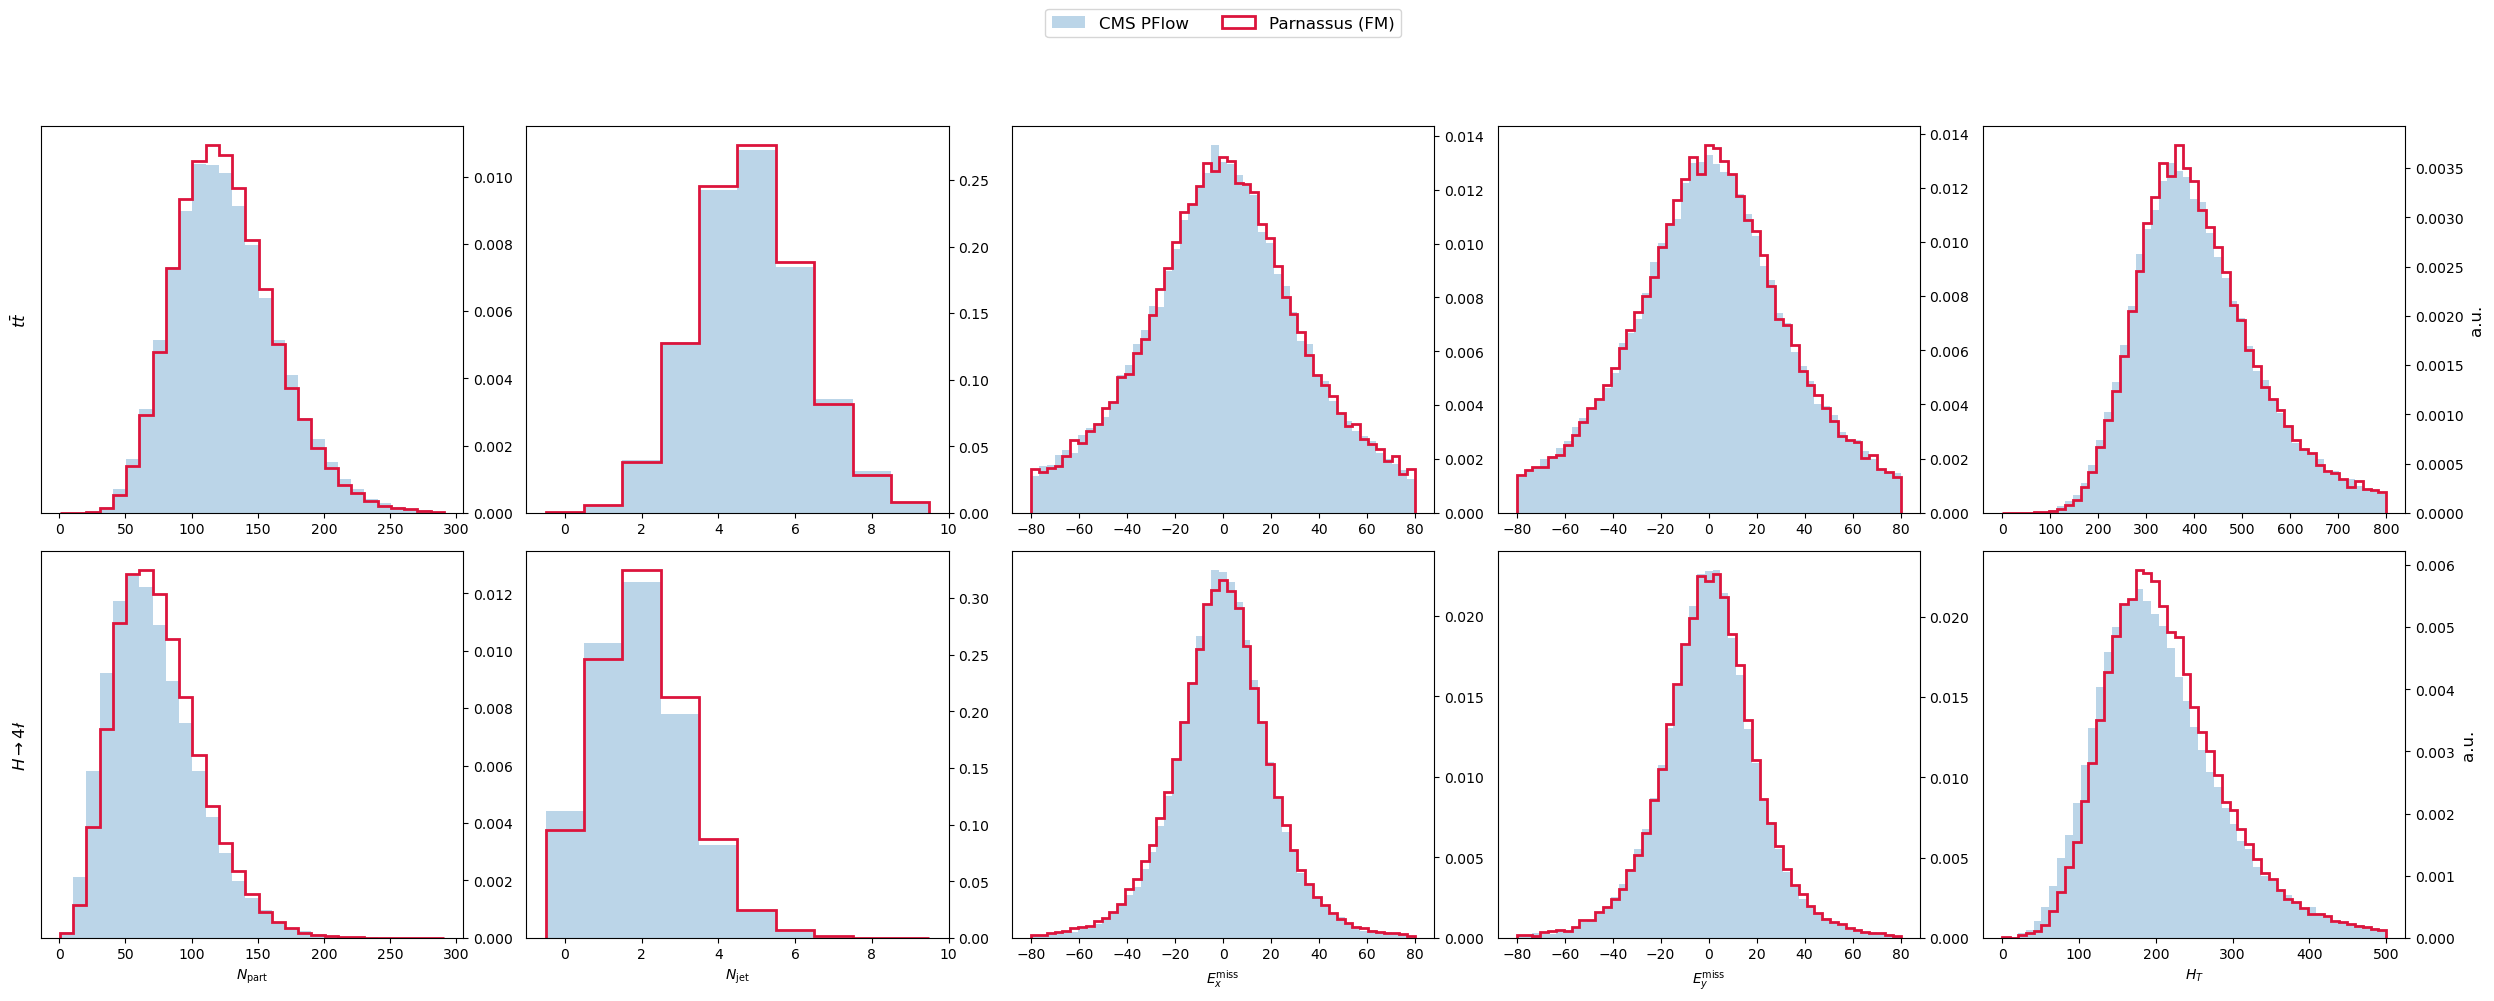

In [17]:
fig = plot_helper.plot_event_features(residuals=False)

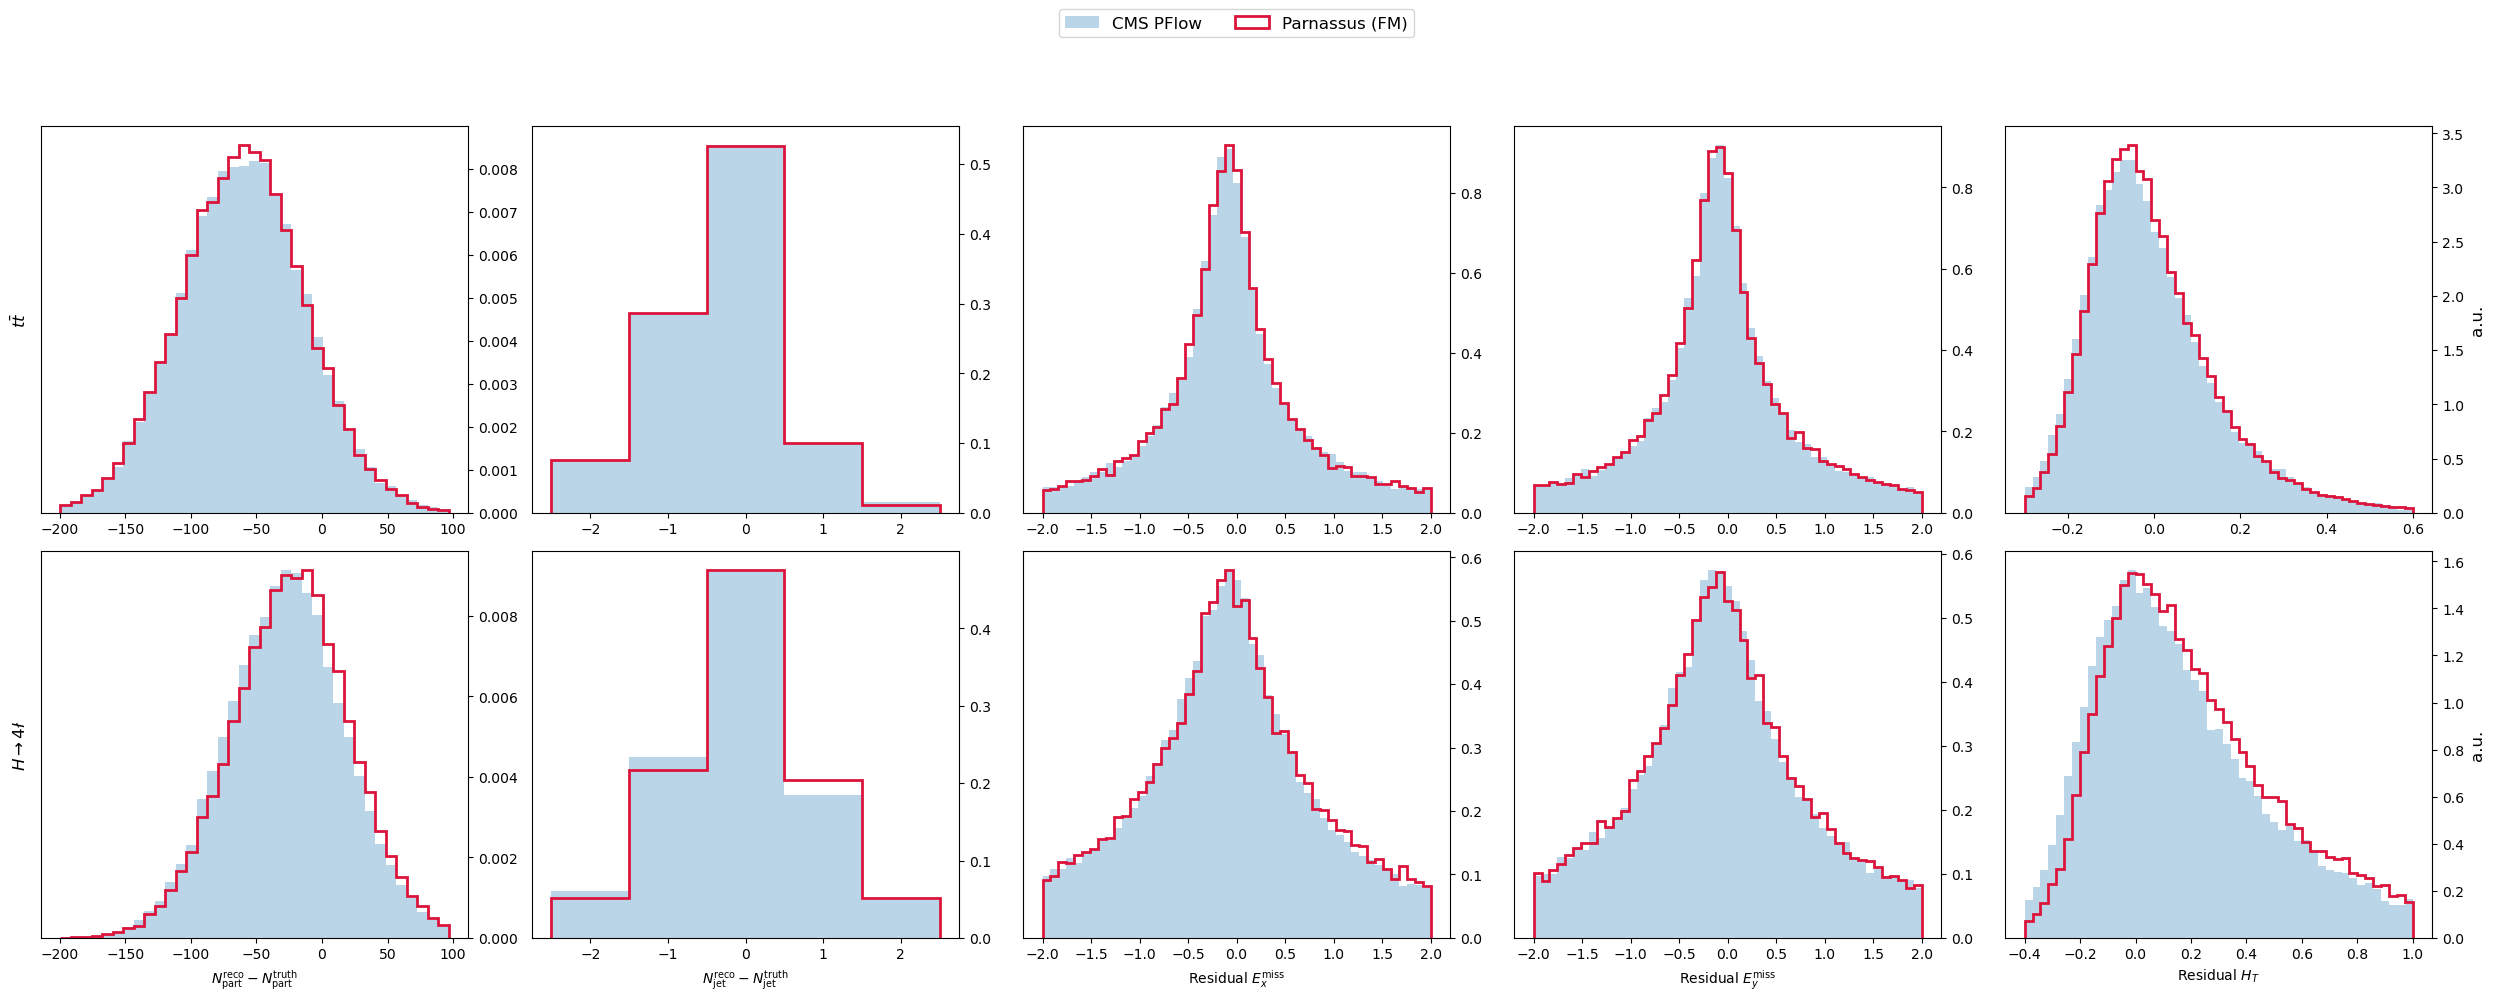

In [18]:
fig = plot_helper.plot_event_features(residuals=True)

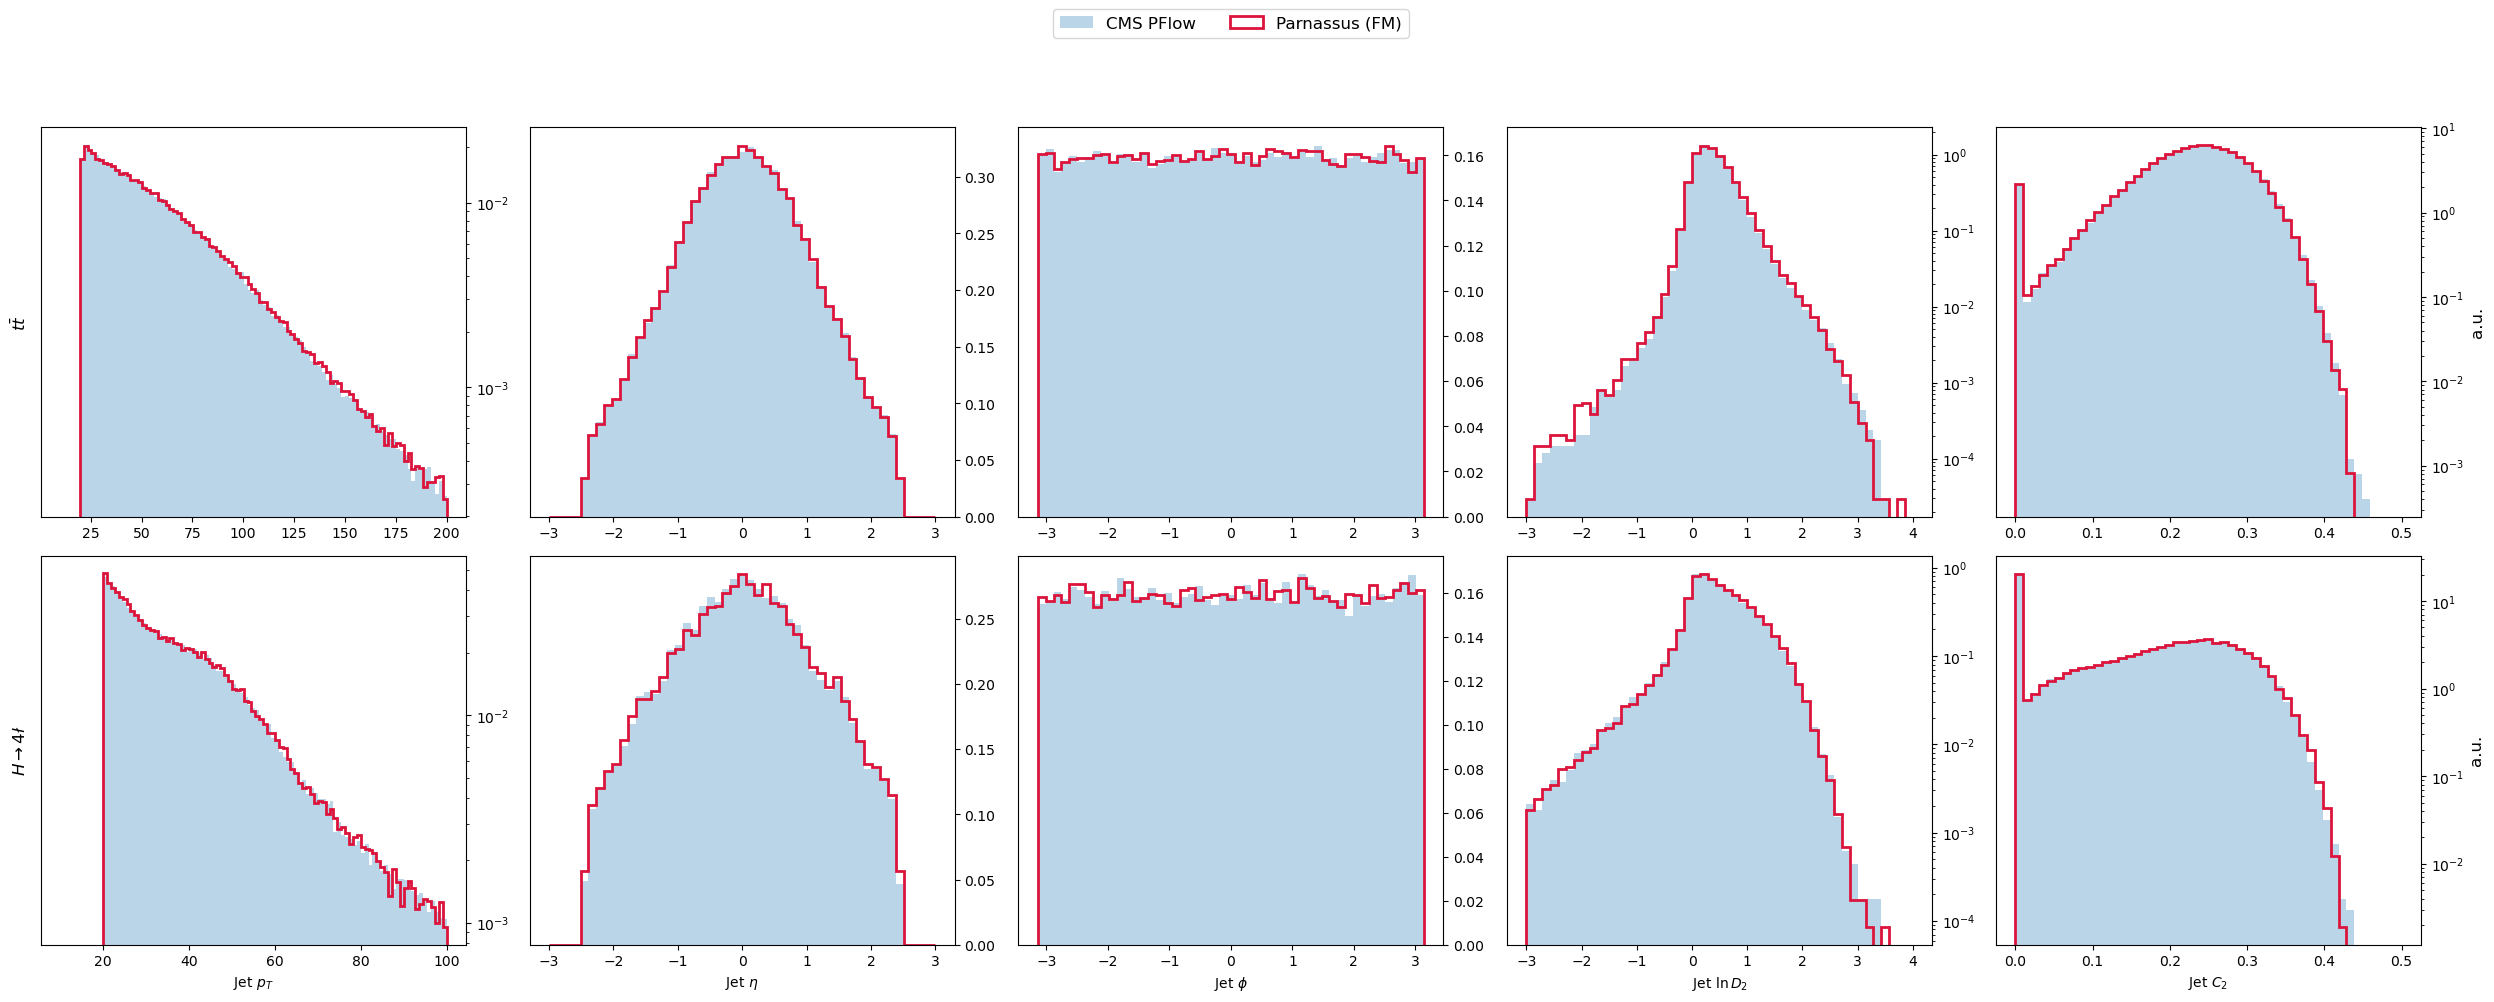

In [19]:
fig = plot_helper.plot_jet_features(log_scale_vars=["pt", "d2", "c2"])

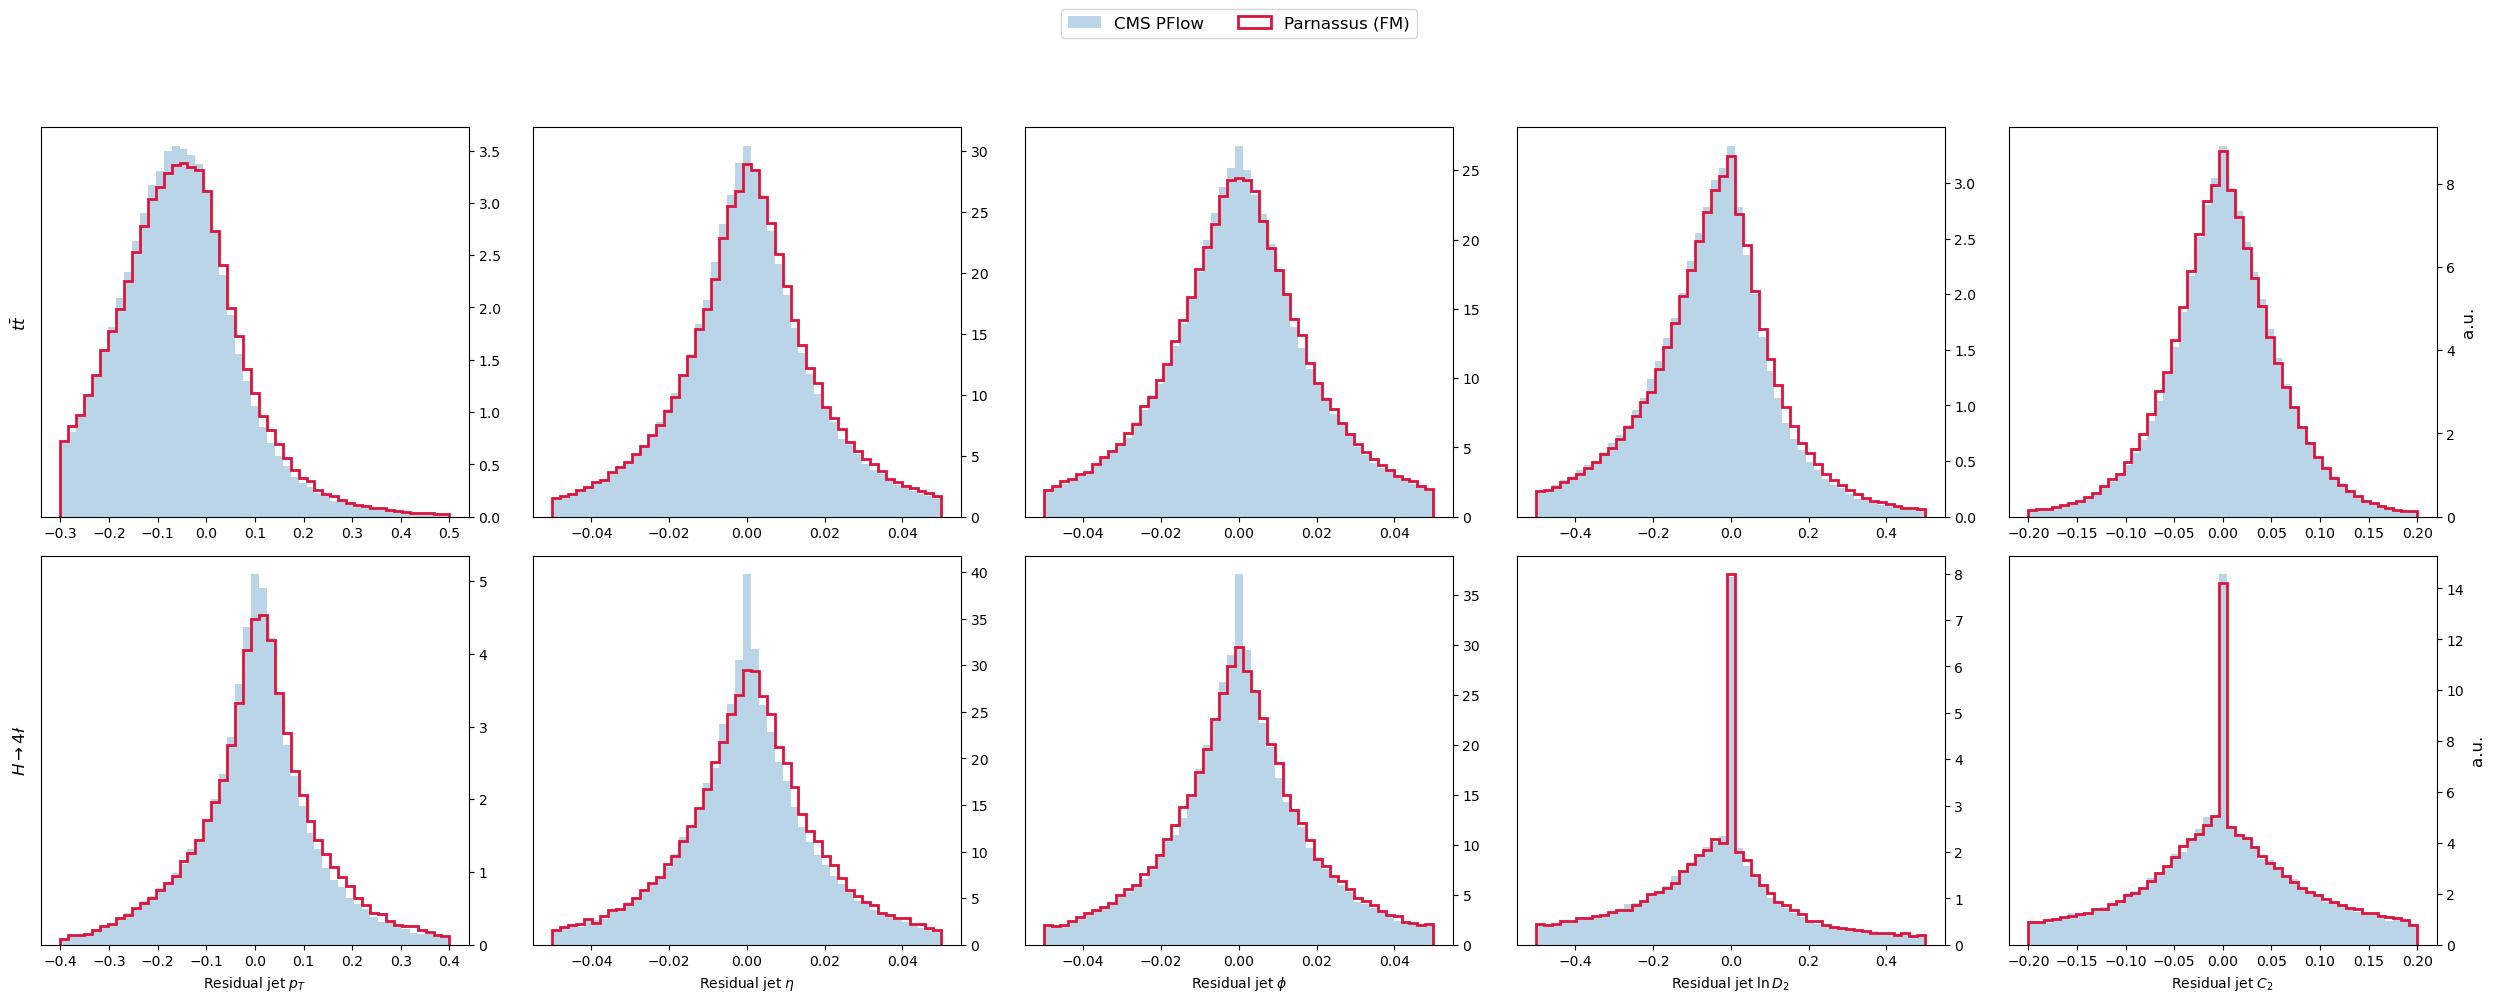

In [20]:
fig = plot_helper.plot_jet_features(residuals=True)

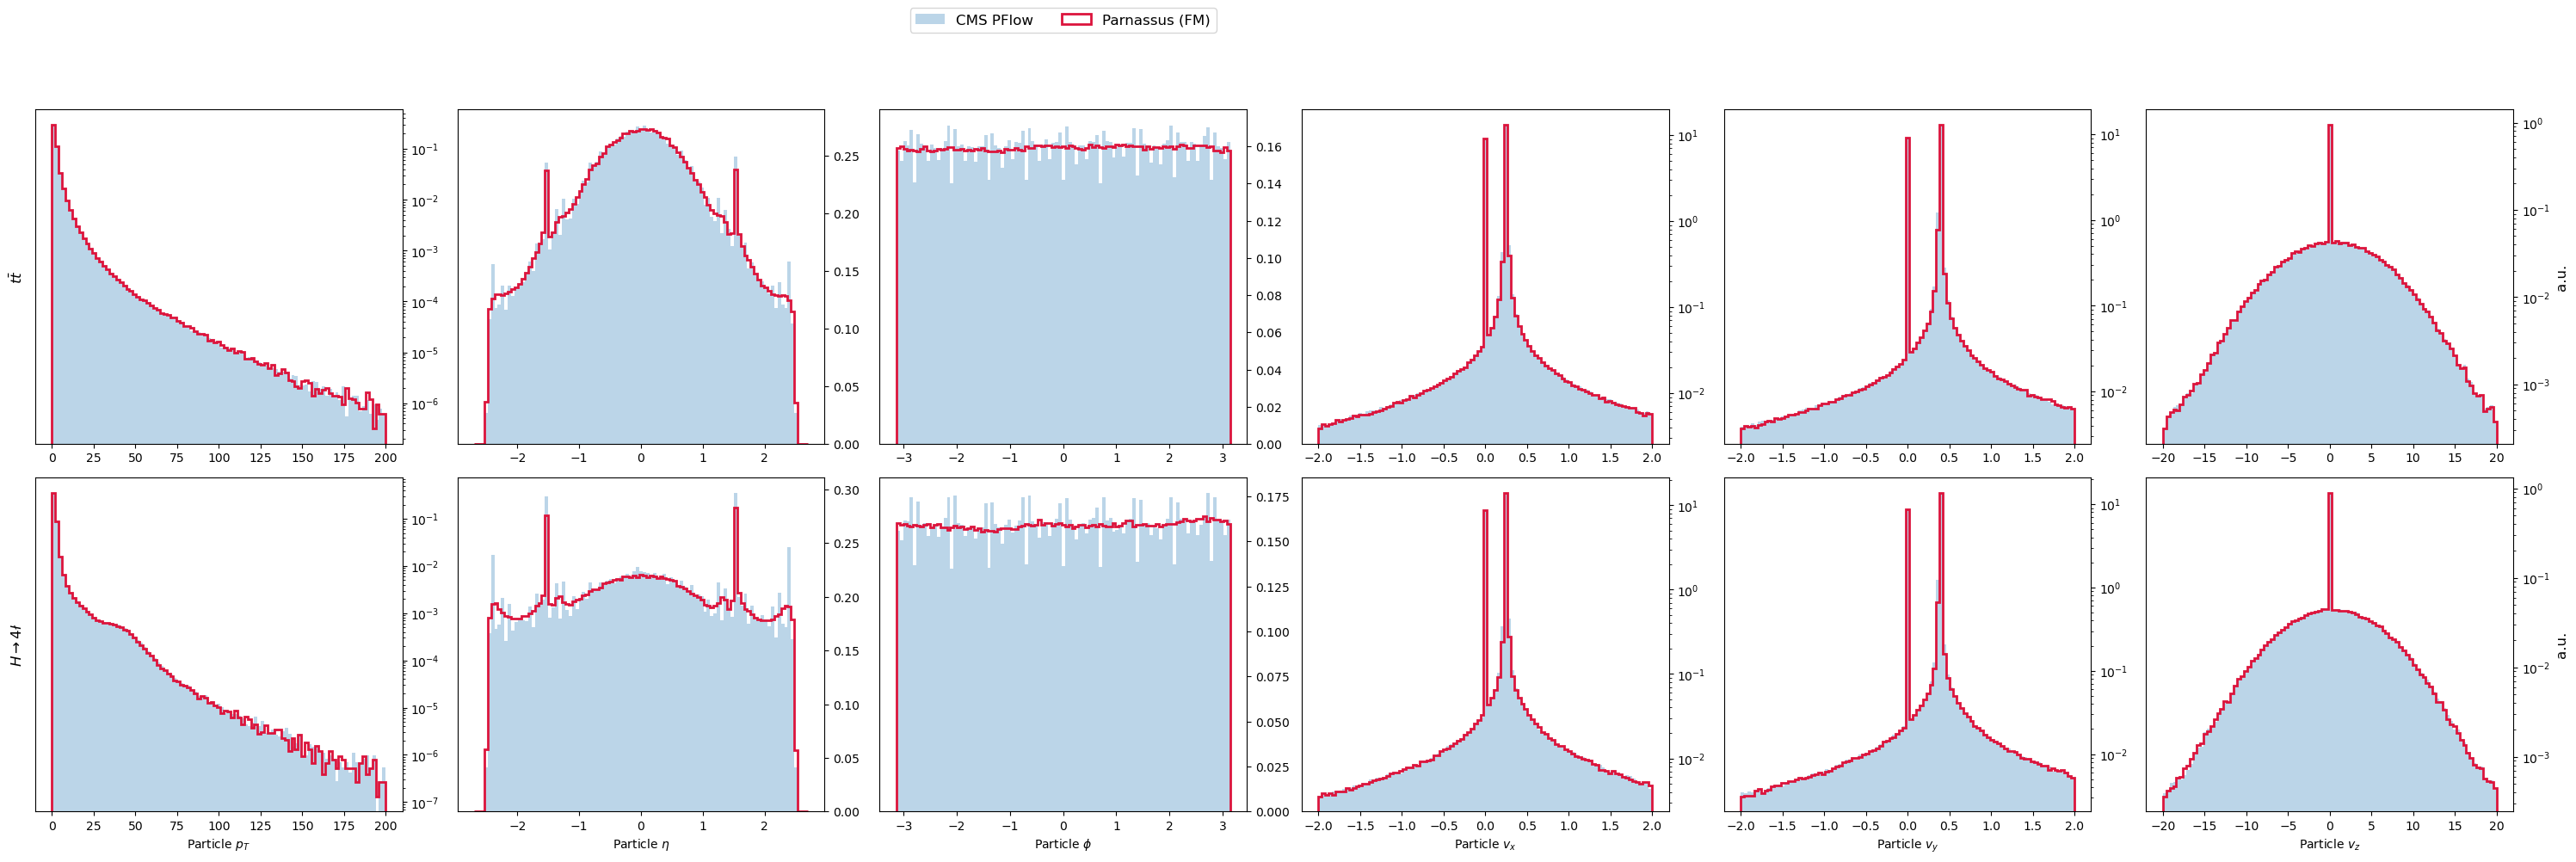

In [21]:
fig = plot_helper.plot_particle_features(log_scale_vars=["pt", "vx", "vy", "vz"])

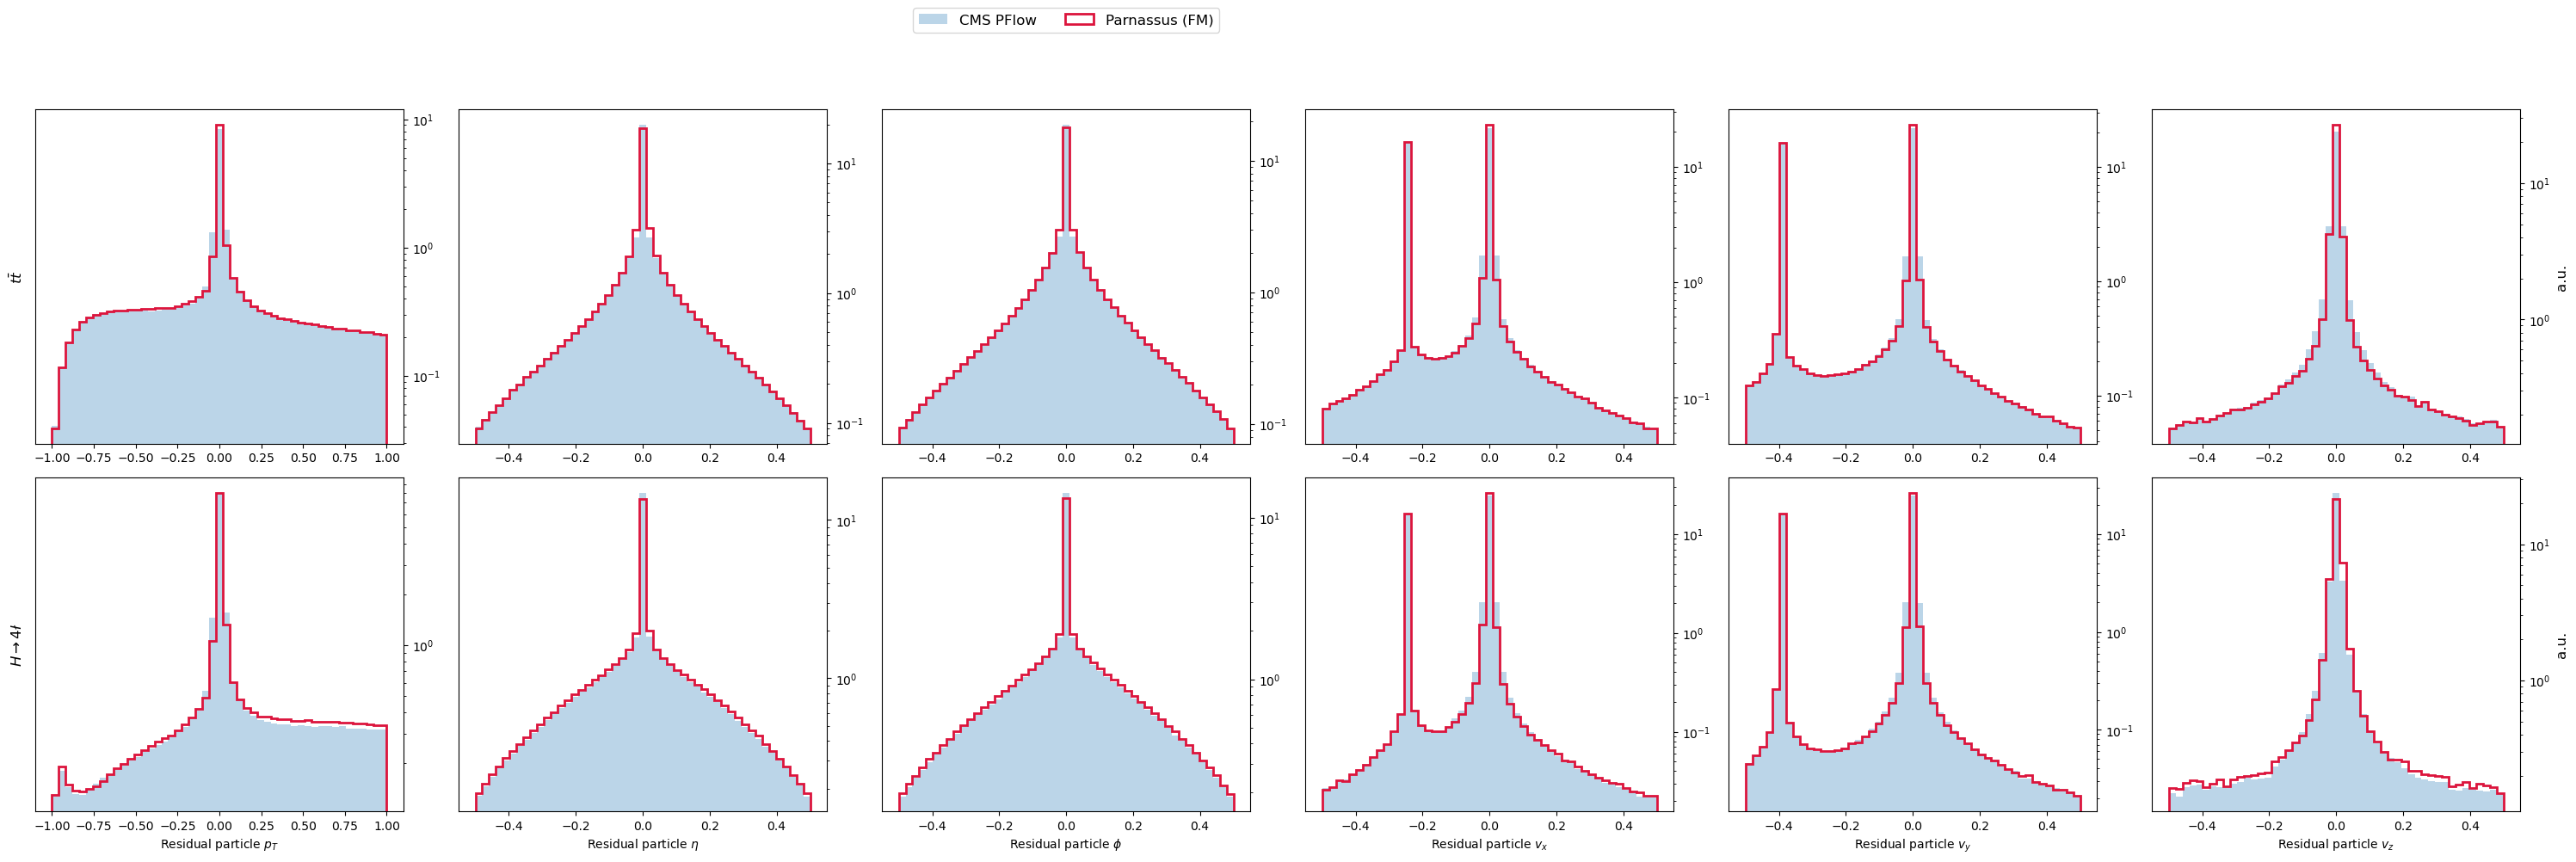

In [22]:
fig = plot_helper.plot_particle_features(residuals=True, log_scale_vars="all")